In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

data = pd.read_csv("data.csv", encoding="latin1")

df = pd.DataFrame(data)
print(df)


       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

            InvoiceDate  UnitPrice  CustomerID         Country  
0        1

In [5]:
print(df.shape)
print(df.info)
print(df.describe())
print(df.dtypes)

(541909, 8)
<bound method DataFrame.info of        InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

            InvoiceDate  UnitPr

In [6]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [7]:
df["Description"] = df["Description"].replace(np.nan,"Nan")

In [8]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [9]:
print(df["CustomerID"].mean())

15287.690570239585


In [10]:
df["CustomerID"] = df["CustomerID"].replace(np.nan,"15287")
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [11]:
print(df.duplicated().sum())

5268


In [12]:


data = data.drop_duplicates().copy()

data['InvoiceDate'] = pd.to_datetime(
    data['InvoiceDate'],
    format='%m/%d/%Y %H:%M'
)

print("Shape after removing duplicates:", data.shape)
print(data.dtypes)


Shape after removing duplicates: (536641, 8)
InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


In [13]:
data['InvoiceDate'] = pd.to_datetime(
    data['InvoiceDate'],
    errors='coerce'
)

print(data['InvoiceDate'].head())

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]


In [ ]:

import pandas as pd
import numpy as np

data = pd.read_csv("data.csv", encoding="latin1")

data.columns = data.columns.str.strip()

data = data.drop_duplicates().copy()

data['InvoiceDate'] = pd.to_datetime(
    data['InvoiceDate'],
    format='%m/%d/%Y %H:%M',
    errors='coerce'
)

print("Data type:", type(data))
print("Shape:", data.shape)
print(data['InvoiceDate'].head())


In [ ]:

print(data.isnull().sum())

In [ ]:
data["CustomerID"] = data["CustomerID"].replace(np.nan,"15287")
print(data.isnull().sum())

In [17]:
data["Description"] = data["Description"].replace(np.nan,"Nan")

In [18]:
data['Revenue'] = data['Quantity'] * data['UnitPrice']

print(data[['Quantity', 'UnitPrice', 'Revenue']].head())

   Quantity  UnitPrice  Revenue
0         6       2.55    15.30
1         6       3.39    20.34
2         8       2.75    22.00
3         6       3.39    20.34
4         6       3.39    20.34


In [19]:
print("Total Revenue:", data['Revenue'].sum())

Total Revenue: 9726006.954


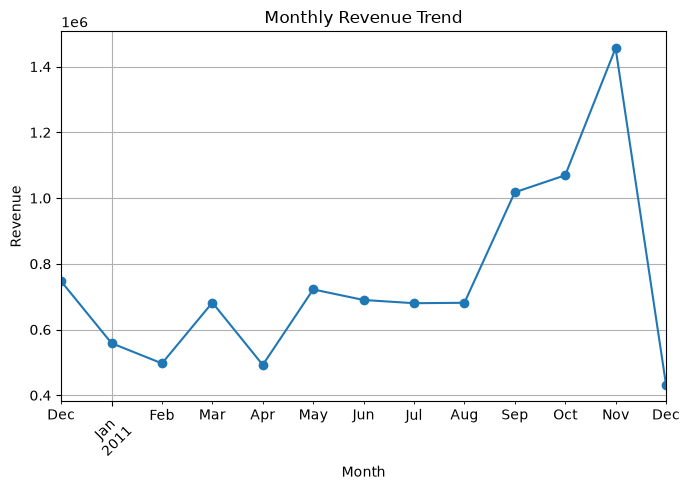

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

data['Month'] = data['InvoiceDate'].dt.to_period('M')

monthly_sales = data.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(7, 5))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


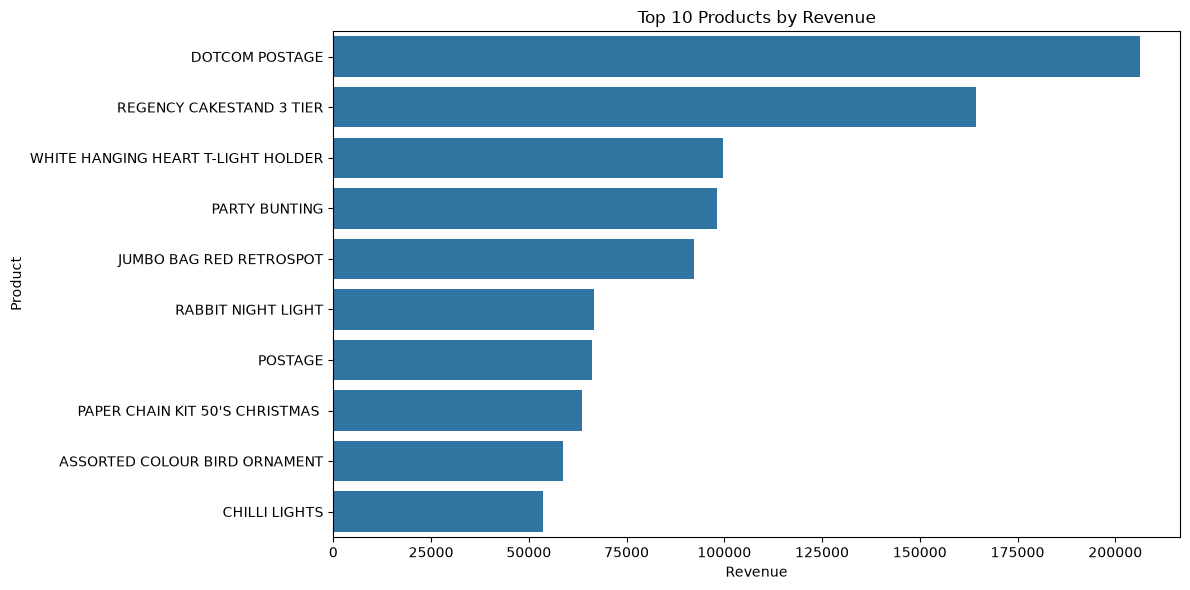

In [23]:

top_products = (
    data.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.show()


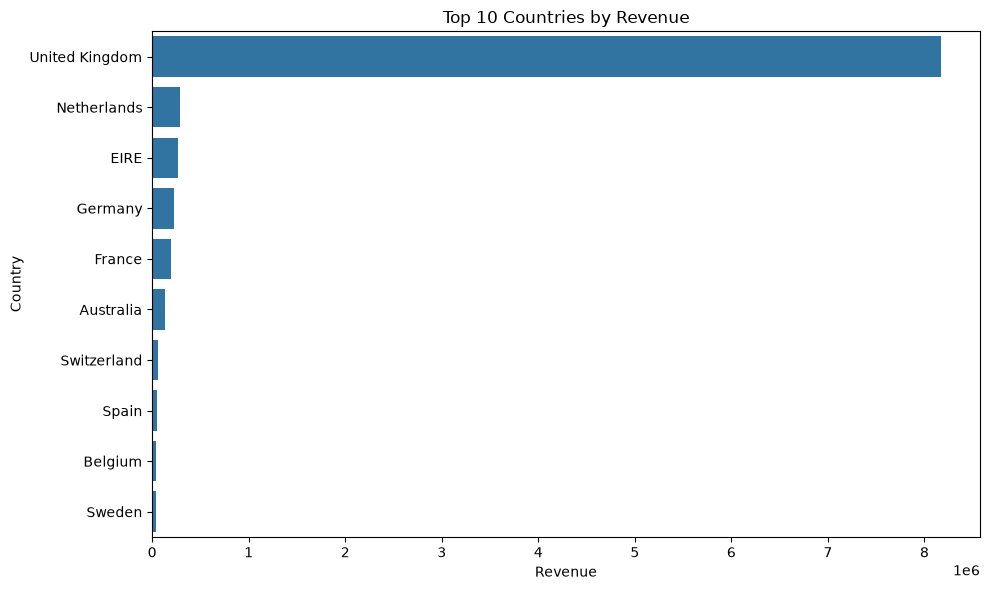

In [24]:

country_sales = (
    data.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=country_sales.values, y=country_sales.index)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


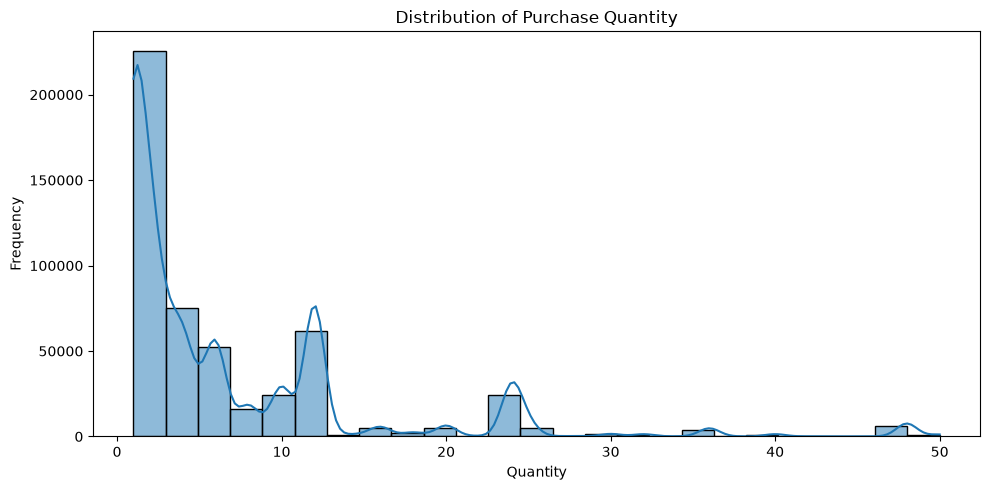

In [26]:

quantity_data = data.loc[
    data['Quantity'].between(1, 50), 'Quantity'
]

plt.figure(figsize=(10, 5))
sns.histplot(quantity_data, bins=25, kde=True)

plt.title('Distribution of Purchase Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


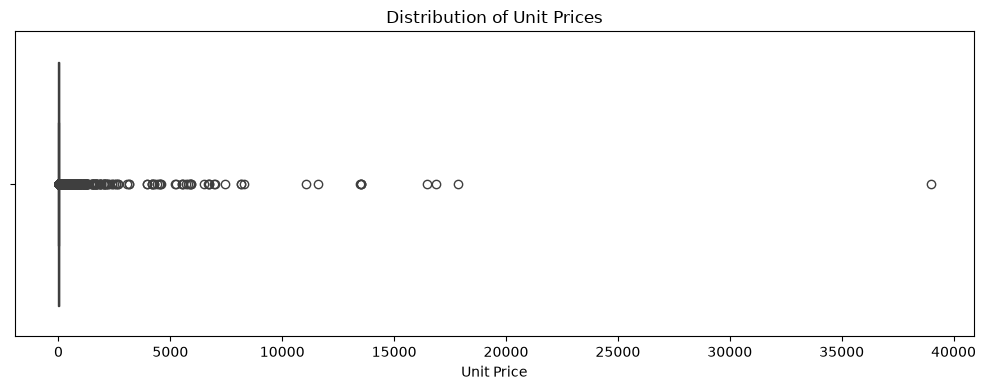

In [27]:

price_data = data.loc[
    data['UnitPrice'] > 0, 'UnitPrice'
]

plt.figure(figsize=(10, 4))
sns.boxplot(x=price_data)

plt.title('Distribution of Unit Prices')
plt.xlabel('Unit Price')
plt.tight_layout()
plt.show()


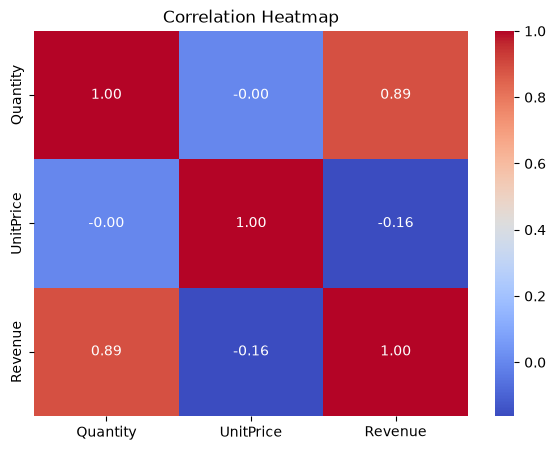

In [31]:

numeric_data = data[
    ['Quantity', 'UnitPrice', 'Revenue']
]

plt.figure(figsize=(7, 5))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
# plt.tight_layout()
plt.show()
